# Sistema de Soporte a la Decisión (DSS) en Desarrollos Inmobiliarios

Analizar el mercado inmobiliario a nivel nacional es un reto debido a la enorme diferencia de precios que existe entre regiones. Para resolver esto, se diseñó una estrategia en tres fases:

Etapa 1 - Segmentar conforme a la ubicación y el precio de mercado y sus características físicas, que van a permitir diferenciar los tipos de inmueble dentro de cada nivel de mercado.

Etapa 2 — Predicción de precio conforme sus características y evaluar si los segmentos identificados en la etapa anterior ayudan a mejorar las predicciones.

Etapa 3 — Optimizar el uso de los precios estimados para evaluar estrategias de comercialización, considerando las restricciones y objetivos financieros de un proyecto inmobiliario.

# Optimización

¿Qué combinación de preventa y venta posterior permite cubrir parte del costo de construcción y alcanzar la rentabilidad esperada, considerando los precios estimados y su incertidumbre?

**Objetivo:**

Encontrar una estrategia de venta que permita cubrir al menos el 80% del presupuesto del proyecto mediante la preventa y alcanzar una rentabilidad del 30%.

Para ello, se busca vender anticipadamente la menor cantidad posible de unidades y mantener los precios posteriores cercanos a los estimados en Predicción.

**Datos:**

Se utilizaron los precios estimados en la etapa de Predicción, junto con sus intervalos de predicción. También se incorporaron las cantidades, superficies y presupuesto del proyecto. 

Los precios estimados se utilizarán como referencia para evaluar las estrategias de preventa y venta.

In [ ]:
# Librerías
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import cvxpy as cp

warnings.filterwarnings("ignore")

## Proyecto Complejo Departamental

**Área promedio de departamentos:**

- 20 Departamentos en PB con Patio: 95.52 $m^2$
- 126 Departamentos sencillos: 71.35 $m^2$
- 2 Departamentos PH: 136.09 $m^2$

**Área promedio por local comercial** 39.34 $m^2$

**Cantidad de comercios:** 5

**Superficie Total $m^2$:** 11,369.38

**Presupuesto total:** $248,834,670.16

**Condiciones financieras:**

- Cobertura de preventa: al menos 80% del presupuesto.
- Rentabilidad objetivo: 30% sobre el costo total.
- Rentabilidad mínima en el escenario conservador: 14%.

La rentabilidad se calcula como la utilidad dividida entre el costo total del proyecto.

**Función objetivo:**

La optimización se divide en dos partes. Primero, se busca cubrir el 80% del presupuesto con la menor cantidad posible de unidades en preventa.

$$\min \sum_{i=1}^{4}q_i$$

Donde $q_i$ representa las unidades de cada tipología destinadas a preventa.

Después se ajustan los precios de las unidades restantes, procurando que sean lo más cercanos posible a los estimados en Predicción.

$$\min\sum_{i=1}^{4}w_i\left(\frac{P_i-p_i}{p_i}\right)^2$$

Donde:
$$
w_i=\frac{(n_i-q_i)a_i}{A_{\text{total}}}
$$

$P_i$ es el precio optimizado por m² y $p_i$ es el precio estimado.

Cuando varias combinaciones permiten alcanzar el objetivo con la misma cantidad de unidades, se elige la que presenta una menor pérdida potencial de ingresos frente a los precios máximos considerados.

**Variables utilizadas:**

- $p_i$: precio estimado por m² en Predicción.
- $L_i$: límite inferior del intervalo.
- $U_i$: límite superior del intervalo.
- $P_i$: precio optimizado de venta posterior.
- $q_i$: cantidad de unidades destinadas a preventa.
- $n_i$: cantidad total de unidades disponibles.
- $a_i$: superficie promedio por unidad.
- $d$: descuento de preventa.
- $C$: presupuesto total del proyecto.

Los ingresos se calculan considerando las unidades vendidas anticipadamente y las unidades restantes a los precios optimizados.

**Restricciones:**

- Los ingresos de preventa deben cubrir al menos el 80% del presupuesto.
- La rentabilidad total debe alcanzar como mínimo el 30%.
- Los precios posteriores deben mantenerse dentro de los límites considerados en Predicción.
- Las unidades destinadas a preventa deben ser enteras y no superar el inventario disponible.
- Se considera una rentabilidad mínima del 14% en un escenario conservador de precios.


### Parámetros

- **Preventa:** cantidad de unidades determinada por el optimizador.
- **Cobertura mínima:** 80% del costo total del proyecto.
- **Descuento de preventa:** 5% sobre el precio estimado por m².
- **Venta posterior:** precios optimizados considerando los intervalos de Predicción.
- **Rentabilidad objetivo:** 30%.
- **Rentabilidad conservadora:** 14%.
- **Escenario conservador:** desplazamiento del 20% desde los precios considerados hacia los límites inferiores, aplicado al inventario pendiente de venta.

El descuento y el escenario conservador se consideran supuestos iniciales de evaluación.

In [ ]:
# Datos del Proyecto

superficie_total =  11369.38

# Departamentos: PB, normal y PH
areas = np.array([95.52, 71.35, 136.09]) 
cantidades = np.array([20, 126, 2]) 

# Locales comerciales
area_comercio = 39.34  
cant_comercio = 5

costo_total = 248_834_670.16

# Condiciones financieras
cobertura_preventa = 0.80
utilidad_meta = 0.30
utilidad_minima = 0.14

ingreso_preventa_objetivo = (cobertura_preventa * costo_total)
ingreso_minimo = ((1 + utilidad_minima) * costo_total)
ingreso_meta = ((1 + utilidad_meta) * costo_total)

# Ubicación del proyecto
colonia = "El Alamo"
municipio = "San Pedro Tlaquepaque"

# Resumen
print("----- PROYECTO INMOBILIARIO -----")
print(f"Ubicación: {colonia}, {municipio}")
print(f"Superficie total: {superficie_total:,.2f} m²")
print(f"Presupuesto: ${costo_total:,.2f}")
print(f"Ingreso de preventa requerido (80%): ${ingreso_preventa_objetivo:,.2f}")
print(f"Ingreso mínimo con rentabilidad del 14%: ${ingreso_minimo:,.2f}")
print(f"Ingreso meta del 30%: ${ingreso_meta:,.2f}")

----- PROYECTO INMOBILIARIO -----
Ubicación: El Alamo, San Pedro Tlaquepaque
Superficie total: 11,369.38 m²
Presupuesto: $248,834,670.16
Ingreso de preventa requerido (80%): $199,067,736.13
Ingreso mínimo con rentabilidad del 14%: $283,671,523.98
Ingreso meta del 30%: $323,485,071.21


Se utilizaron los precios obtenidos en Predicción para los tres tipos de departamentos. Para los locales comerciales se tomó como referencia un precio de $25,000 por m², con un mínimo de $20,000 y un máximo de $30,000.

Estos valores de los locales son supuestos comerciales, ya que no fueron estimados por el modelo predictivo.

In [ ]:
# Integración de datos etapa 2 y comercio
archivo = Path("precios_torres_dss.csv")

if not archivo.exists():
    raise FileNotFoundError(
        "Ejecuta la celda de precios de referencia para torre del notebook de Predicción")

# Predicciones de departamentos
pred = pd.read_csv(archivo).rename(columns={
    "Limite_inferior_m2": "Lim_inf",
    "Limite_superior_m2": "Lim_sup"})

# Comercio: referencia provisional del modelo original
com = pd.DataFrame([{
    "Tipologia": "Comercio",
    "Cantidad": cant_comercio,
    "Area_m2": area_comercio,
    "Precio_m2": 25_000,
    "Lim_inf": 20_000,
    "Lim_sup": 30_000 }])

# Unificar datos
df = pd.concat([com, pred], ignore_index=True)

# Conservar el orden de las cuatro tipologías
orden = ["Comercio","PB con patio","Departamento sencillo","Penthouse"]

df = df.set_index("Tipologia").reindex(orden)

# Verificar columnas y valores
columnas = ["Cantidad", "Area_m2","Precio_m2", "Lim_inf", "Lim_sup"]

if df[columnas].isna().any().any():
    raise ValueError("Faltan datos o tipologías en el archivo.")

for col in columnas:
    df[col] = pd.to_numeric(df[col], errors="raise")

if not np.isfinite(df[columnas].to_numpy()).all():
    raise ValueError("Se encontraron valores no finitos.")

if ((df[columnas] <= 0).any().any()
    or (df["Lim_inf"] > df["Precio_m2"]).any()
    or (df["Precio_m2"] > df["Lim_sup"]).any()):
    raise ValueError(
        "Los precios o intervalos no son válidos.")

# Comprobar concordancia con el proyecto original
if not np.array_equal(
    df.loc[orden[1:], "Cantidad"].to_numpy(),cantidades):
    raise ValueError("Las cantidades no coinciden.")

if not np.allclose(
    df.loc[orden[1:], "Area_m2"].to_numpy(),areas):
    raise ValueError("Las áreas no coinciden.")

df = df.reset_index()

display(df)

,Tipologia,Cantidad,Area_m2,Precio_m2,Lim_inf,Lim_sup,Cluster,Precio_estimado
0,Comercio,5,39.34,25000.000000,20000.000000,30000.000000,NaN,NaN
1,PB con patio,20,95.52,31228.391960,14220.840452,43536.633585,D5,2982936.00
2,Departamento sencillo,126,71.35,34640.725298,18889.297968,56544.661388,D5,2471615.75
3,Penthouse,2,136.09,29764.578588,14727.358439,58855.410317,D7,4050661.50


In [ ]:
# Parámetros de Optimización

# Inventario y superficies
n = df["Cantidad"].to_numpy(dtype=int)
a = df["Area_m2"].to_numpy(dtype=float)

# Superficie total por tipología
A = n * a

# Precios centrales de Predicción
ph = df["Precio_m2"].to_numpy(dtype=float)

# Intervalos de Predicción
L = df["Lim_inf"].to_numpy(dtype=float)
U = df["Lim_sup"].to_numpy(dtype=float)

# Descuento de preventa
descuento = 0.05

# Precio de preventa
precio_preventa = ph * (1 - descuento)

# Ajuste conservador del 20%
riesgo = 0.20

# Comprobaciones
assert np.isclose(A.sum(), superficie_total)
assert np.all(L <= ph)
assert np.all(ph <= U)
assert np.all(precio_preventa <= U)

print("=== REFERENCIAS DE PREDICCIÓN ===")
print(f"Unidades totales: {n.sum()}")
print(f"Superficie: {A.sum():,.2f} m²")
print(f"Ingreso a precios predichos: ${np.sum(A * ph):,.2f}")

display(df)

=== REFERENCIAS DE PREDICCIÓN ===
Unidades totales: 153
Superficie: 11,369.38 m²
Ingreso a precios predichos: $384,101,127.50


,Tipologia,Cantidad,Area_m2,Precio_m2,Lim_inf,Lim_sup,Cluster,Precio_estimado
0,Comercio,5,39.34,25000.000000,20000.000000,30000.000000,NaN,NaN
1,PB con patio,20,95.52,31228.391960,14220.840452,43536.633585,D5,2982936.00
2,Departamento sencillo,126,71.35,34640.725298,18889.297968,56544.661388,D5,2471615.75
3,Penthouse,2,136.09,29764.578588,14727.358439,58855.410317,D7,4050661.50


### Optimización

Primero se calcula cuántas unidades deben venderse en preventa para cubrir el presupuesto establecido. Después se revisan los precios del inventario restante para comprobar que se alcance la rentabilidad esperada.

Por último, se analizan diferentes escenarios para observar cómo cambiarían los resultados si los precios de venta disminuyeran.

In [ ]:
# Optimización - Preventa

def optimizar_preventa():

    # Variable: unidades enteras de preventa
    q = cp.Variable(len(n), integer=True)

    # Superficie de preventa por tipología
    superficie_pre = cp.multiply(q, a)

    # Ingreso de preventa
    ingreso_pre = cp.sum(cp.multiply(superficie_pre, precio_preventa))

    # Unidades restantes para venta posterior
    unidades_restantes = n - q

    superficie_restante = cp.multiply(unidades_restantes, a)

    # Máximo ingreso posterior permitido por los límites superiores
    ingreso_venta_max = cp.sum(cp.multiply(superficie_restante, U))

    # Límite superior desplazado 20% hacia L
    U_conservador = U - riesgo * (U - L)

    ingreso_venta_conservador_max = cp.sum(
        cp.multiply(
            superficie_restante, U_conservador))

    # Restricciones
    restricciones = [
        q >= 0,
        q <= n ,

        # Cubrir 80% del presupuesto
        ingreso_pre >= ingreso_preventa_objetivo,

        # Con precios en U se podría alcanzar el 30%
        ingreso_pre + ingreso_venta_max >= ingreso_meta,

        # Verificar rentabilidad mínima del 14%
        ingreso_pre + ingreso_venta_conservador_max
        >= ingreso_minimo
    ]

    # Objetivo: menor número de unidades
    problema = cp.Problem(cp.Minimize(cp.sum(q)),restricciones)
    problema.solve(solver=cp.SCIPY)

    if problema.status != "optimal":
        raise ValueError(
            "No existe una preventa factible con las condiciones establecidas.")

    minimo_unidades = int(round(np.sum(q.value)))

    # Elegir la distribución con menor pérdida potencial
    restricciones.append(cp.sum(q) == minimo_unidades)
    perdida_potencial = cp.sum(cp.multiply(superficie_pre,U - precio_preventa))
    segundo_problema = cp.Problem(cp.Minimize(perdida_potencial),restricciones)
    segundo_problema.solve(solver=cp.SCIPY)

    if segundo_problema.status != "optimal":
        raise ValueError(
            "No se pudo seleccionar la distribución de preventa.")

    unidades_preventa = np.rint(q.value).astype(int)
    unidades_venta = n - unidades_preventa
    ingreso_preventa = float(np.sum(unidades_preventa * a * precio_preventa))

    return {
        "unidades_preventa": unidades_preventa,
        "unidades_venta": unidades_venta,
        "ingreso_preventa": ingreso_preventa,
        "porcentaje_preventa":
            unidades_preventa.sum() / n.sum()
    }


resultado_preventa = optimizar_preventa()

print("=== OPTIMIZACIÓN DE PREVENTA ===")
print(
    "Unidades preventa:",
    resultado_preventa["unidades_preventa"].sum())

print(
    "Unidades restantes:",
    resultado_preventa["unidades_venta"].sum())

print(f"Porcentaje preventa: {resultado_preventa['porcentaje_preventa']:.2%}")
print(f"Ingreso de preventa: ${resultado_preventa['ingreso_preventa']:,.2f}")

print(
    f"Cobertura del presupuesto: "
    f"{resultado_preventa['ingreso_preventa']/costo_total:.2%}")


=== OPTIMIZACIÓN DE PREVENTA ===
Unidades preventa: 80
Unidades restantes: 73
Porcentaje preventa: 52.29%
Ingreso de preventa: $199,144,358.71
Cobertura del presupuesto: 80.03%


In [ ]:
# Optimización - Precios de venta

def optimizar_precios(resultado_preventa):

    unidades_pre = resultado_preventa["unidades_preventa"]
    unidades_venta = resultado_preventa["unidades_venta"]
    ingreso_pre = resultado_preventa["ingreso_preventa"]

    # VARIABLE DE DECISIÓN

    # Multiplicador del precio predicho
    # x = 1 significa precio igual a Predicción
    x = cp.Variable(len(n))

    # Precio posterior por m²
    P = cp.multiply(ph, x)

    superficie_venta = unidades_venta * a

    # INGRESOS EN MILLONES DE PESOS

    ingreso_pre_M = ingreso_pre / 1e6
    ingreso_venta_M = (cp.sum(cp.multiply(superficie_venta, P)) / 1e6)
    ingreso_total_M = (ingreso_pre_M + ingreso_venta_M)

    # ESCENARIO CONSERVADOR

    # Ajuste de precios hacia el límite inferior
    P_conservador = (P - riesgo * (P - L))

    ingreso_conservador_M = (
        ingreso_pre_M
        + cp.sum(
            cp.multiply(superficie_venta,P_conservador)) / 1e6)

    # RESTRICCIONES

    restricciones = [

        # Intervalos de Predicción
        x >= L / ph,
        x <= U / ph,

        # Rentabilidad central mínima 30%
        ingreso_total_M >= ingreso_meta / 1e6,

        # Rentabilidad conservadora mínima 14%
        ingreso_conservador_M >= ingreso_minimo / 1e6
    ]

    # Conservar el precio cuando no quedan unidades
    sin_venta = unidades_venta == 0

    if np.any(sin_venta):
        restricciones.append(x[sin_venta] == 1)

    # FUNCIÓN OBJETIVO

    # Ponderación por superficie restante
    pesos = (superficie_venta / superficie_total)

    # Minimizar ajustes relativos respecto a los precios predichos
    objetivo = cp.Minimize(
        cp.sum(cp.multiply(pesos,cp.square(x - 1))))

    problema = cp.Problem(objetivo, restricciones)

    problema.solve(solver=cp.CLARABEL)

    print("Estado del solucionador:", problema.status)

    if problema.status not in (
        "optimal", "optimal_inaccurate"
    ):
        raise ValueError(
            "No se encontró solución factible. "
            "Revisa el diagnóstico financiero.")

    # Resultados
    precios_venta = (ph * np.asarray(x.value).ravel())

    ingreso_venta = float(np.sum(superficie_venta * precios_venta))
    ingreso_total = ingreso_pre + ingreso_venta
    utilidad = ingreso_total - costo_total
    rentabilidad = utilidad / costo_total

    # Escenario conservador
    precios_conservadores = (precios_venta- riesgo * (precios_venta - L))

    ingreso_conservador = (ingreso_pre+ np.sum(superficie_venta * precios_conservadores))

    rentabilidad_conservadora = (ingreso_conservador - costo_total) / costo_total

    return {
        "estado": problema.status,
        "precios_venta": precios_venta,
        "ingreso_preventa": ingreso_pre,
        "ingreso_venta": ingreso_venta,
        "ingreso_total": ingreso_total,
        "utilidad": utilidad,
        "rentabilidad": rentabilidad,
        "ingreso_conservador": ingreso_conservador,
        "rentabilidad_conservadora":
            rentabilidad_conservadora
    }

# EJECUCIÓN

resultado_precios = optimizar_precios(resultado_preventa)

print("\n=== RESULTADOS DE OPTIMIZACIÓN ===")

print(f"Ingreso preventa: ${resultado_precios['ingreso_preventa']:,.2f}")
print(f"Ingreso venta posterior: ${resultado_precios['ingreso_venta']:,.2f}")
print(f"Ingreso total: ${resultado_precios['ingreso_total']:,.2f}")
print(f"Utilidad: ${resultado_precios['utilidad']:,.2f}")
print(f"Rentabilidad central: {resultado_precios['rentabilidad']:.2%}")
print(f"Rentabilidad conservadora: {resultado_precios['rentabilidad_conservadora']:.2%}")

Estado del solucionador: optimal

=== RESULTADOS DE OPTIMIZACIÓN ===
Ingreso preventa: $199,144,358.71
Ingreso venta posterior: $174,475,485.46
Ingreso total: $373,619,844.18
Utilidad: $124,785,174.02
Rentabilidad central: 50.15%
Rentabilidad conservadora: 43.85%


In [ ]:
# Estrategia de comercialización

tabla = df[
    ["Tipologia", "Cantidad", "Area_m2",
     "Precio_m2", "Lim_inf", "Lim_sup"]
].copy()

# Unidades optimizadas
tabla["Unidades_preventa"] = (resultado_preventa["unidades_preventa"])

tabla["Unidades_venta"] = (resultado_preventa["unidades_venta"])

# Precios
tabla["Precio_preventa_m2"] = precio_preventa
tabla["Precio_venta_m2"] = (resultado_precios["precios_venta"])

# Ingresos por tipología
tabla["Ingreso_preventa"] = (
    tabla["Unidades_preventa"]
    * tabla["Area_m2"]
    * tabla["Precio_preventa_m2"]
)

tabla["Ingreso_venta"] = (
    tabla["Unidades_venta"]
    * tabla["Area_m2"]
    * tabla["Precio_venta_m2"]
)

# Diferencia respecto a Predicción
tabla["Ajuste_venta_pct"] = (
    tabla["Precio_venta_m2"]
    / tabla["Precio_m2"] - 1
) * 100

print("=== ESTRATEGIA COMERCIAL ===")
display(tabla.round(2))

print("\n=== RESUMEN FINANCIERO ===")
print(f"Unidades en preventa: {tabla['Unidades_preventa'].sum()}")
print(f"Unidades en venta posterior: {tabla['Unidades_venta'].sum()}")

print(f"Porcentaje de preventa: {resultado_preventa['porcentaje_preventa']:.2%}")
print(f"Cobertura del costo: {resultado_preventa['ingreso_preventa']/costo_total:.2%}")
print(f"Ingreso total: ${resultado_precios['ingreso_total']:,.2f}")
print(f"Utilidad: ${resultado_precios['utilidad']:,.2f}")
print(f"Rentabilidad: {resultado_precios['rentabilidad']:.2%}")

print(
    "Cumple cobertura 80%:",
    resultado_preventa["ingreso_preventa"]>= ingreso_preventa_objetivo - 1)

print(
    "Cumple rentabilidad 30%:",
    resultado_precios["ingreso_total"]>= ingreso_meta - 1)


=== ESTRATEGIA COMERCIAL ===


,Tipologia,Cantidad,Area_m2,Precio_m2,Lim_inf,Lim_sup,Unidades_preventa,Unidades_venta,Precio_preventa_m2,Precio_venta_m2,Ingreso_preventa,Ingreso_venta,Ajuste_venta_pct
0,Comercio,5,39.34,25000.00,20000.00,30000.00,1,4,23750.00,24999.99,9.343250e+05,3.933998e+06,-0.0
1,PB con patio,20,95.52,31228.39,14220.84,43536.63,20,0,29666.97,31228.39,5.667578e+07,0.000000e+00,0.0
2,Departamento sencillo,126,71.35,34640.73,18889.30,56544.66,57,69,32908.69,34640.73,1.338380e+08,1.705415e+08,0.0
3,Penthouse,2,136.09,29764.58,14727.36,58855.41,2,0,28276.35,29764.58,7.696257e+06,0.000000e+00,-0.0



=== RESUMEN FINANCIERO ===
Unidades en preventa: 80
Unidades en venta posterior: 73
Porcentaje de preventa: 52.29%
Cobertura del costo: 80.03%
Ingreso total: $373,619,844.18
Utilidad: $124,785,174.02
Rentabilidad: 50.15%
Cumple cobertura 80%: True
Cumple rentabilidad 30%: True


Para cubrir el 80% del presupuesto con la menor cantidad de unidades, el modelo seleccionó las 20 plantas bajas con patio, los 2 penthouses, 57 departamentos sencillos y 1 local comercial.

En cuanto a los precios posteriores, no fue necesario hacer ajustes, ya que con los valores de Predicción se alcanza una rentabilidad superior al 30%.

In [ ]:
# Diagnóstico e incertidumbre

def evaluar_escenario(factor):
    ingreso_pre = resultado_preventa["ingreso_preventa"]

    precios_escenario = (
        resultado_precios["precios_venta"]- factor * (resultado_precios["precios_venta"] - L))

    ingreso_venta = np.sum(resultado_preventa["unidades_venta"]* a * precios_escenario)

    ingreso_total = ingreso_pre + ingreso_venta

    rentabilidad = (ingreso_total - costo_total) / costo_total

    return ingreso_total, rentabilidad


escenarios = []

for factor in [0, 0.20, 0.50, 1.00]:

    ingreso, rentabilidad = evaluar_escenario(factor)

    escenarios.append({
        "Escenario": f"{factor:.0%} hacia L",
        "Ingreso": ingreso,
        "Rentabilidad_pct": rentabilidad * 100,
        "Cubre_costo": ingreso >= costo_total,
        "Cumple_30": ingreso >= ingreso_meta
    })

df_escenarios = pd.DataFrame(escenarios)

print("=== ANÁLISIS DE INCERTIDUMBRE ===")
display(df_escenarios.round(2))

# Comprobación del escenario conservador
ingreso_20, rentabilidad_20 = (
    evaluar_escenario(riesgo))

print(f"Rentabilidad conservadora: {rentabilidad_20:.2%}")

print(
    "Cumple mínimo 14%:",ingreso_20 >= ingreso_minimo - 1)


=== ANÁLISIS DE INCERTIDUMBRE ===


,Escenario,Ingreso,Rentabilidad_pct,Cubre_costo,Cumple_30
0,0% hacia L,3.736198e+08,50.15,True,True
1,20% hacia L,3.579532e+08,43.85,True,True
2,50% hacia L,3.344531e+08,34.41,True,True
3,100% hacia L,2.952864e+08,18.67,True,False


Rentabilidad conservadora: 43.85%
Cumple mínimo 14%: True


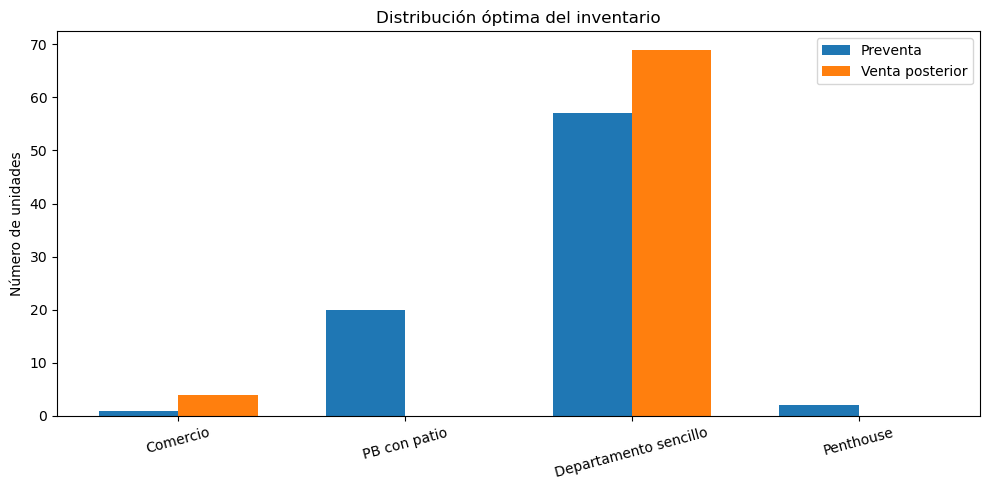

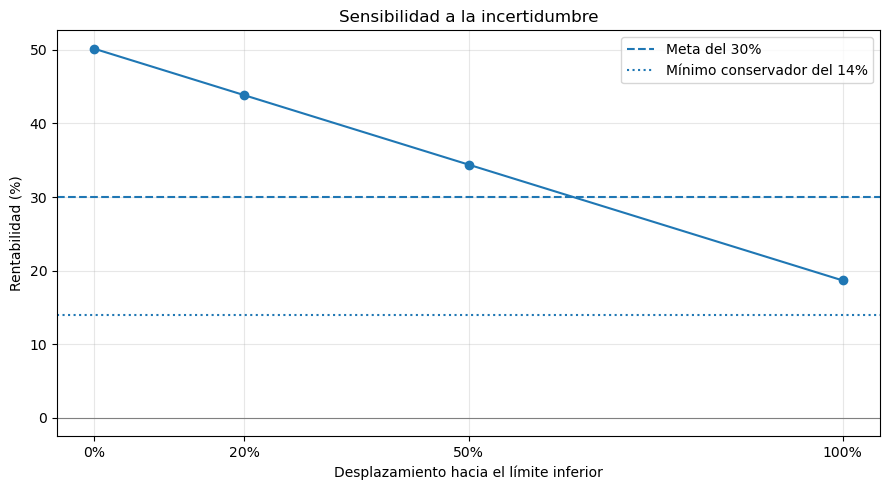

In [ ]:
# Visualización de resultados

# Gráfica 1. Distribución del inventario
x = np.arange(len(df))
ancho = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - ancho / 2,
    resultado_preventa["unidades_preventa"],
    ancho,
    label="Preventa")

plt.bar(
    x + ancho / 2,
    resultado_preventa["unidades_venta"],
    ancho,
    label="Venta posterior")

plt.xticks(x, df["Tipologia"], rotation=15)
plt.ylabel("Número de unidades")
plt.title("Distribución óptima del inventario")
plt.legend()
plt.tight_layout()
plt.show()


# Gráfica 2. Rentabilidad por escenario
plt.figure(figsize=(9, 5))

factores = np.array([0, 20, 50, 100])

plt.plot(
    factores,
    df_escenarios["Rentabilidad_pct"],
    marker="o")

plt.xticks(factores, [f"{f}%" for f in factores])
plt.xlabel("Desplazamiento hacia el límite inferior")

plt.axhline(
    30, linestyle="--",
    label="Meta del 30%")

plt.axhline(
    14, linestyle=":",
    label="Mínimo conservador del 14%")

plt.axhline(0, color="gray", linewidth=0.8)
plt.ylabel("Rentabilidad (%)")
plt.title("Sensibilidad a la incertidumbre")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Para conocer cómo podrían cambiar los resultados, se analizaron diferentes escenarios en los que disminuyen los precios de las unidades pendientes de venta.

La rentabilidad inicial es de 50.15%, pero baja a 43.85% cuando los precios disminuyen un 20% hacia sus límites inferiores. Con una reducción del 50% dentro de esos rangos, la rentabilidad llega a 34.41%, mientras que al alcanzar los límites inferiores queda en 18.67%.

Esto muestra que el proyecto podría soportar algunas disminuciones de precios, aunque la meta del 30% dejaría de cumplirse cuando el desplazamiento fuera mayor al 64% aproximadamente.

En estos cálculos se mantienen fijos los ingresos de preventa, aunque también son estimaciones. Por ello, los resultados podrían cambiar si esas ventas se realizaran a precios menores.

# Conclusión

Con los resultados de Segmentación y Predicción se pudo desarrollar una estrategia de comercialización para el proyecto inmobiliario.

El modelo determinó que se necesitan 80 unidades en preventa, equivalentes al 52.29% del inventario, para cubrir poco más del 80% del presupuesto. Además, se obtuvo una rentabilidad estimada del 50.15%, superando la meta del 30%.

Al analizar distintos escenarios se encontró que la rentabilidad podría disminuir hasta 18.67% si las unidades pendientes se vendieran en sus precios mínimos estimados, manteniendo fija la preventa.

En general, esta etapa permitió conocer una posible forma de distribuir las ventas y evaluar cómo podrían cambiar los resultados según los precios que se consigan.